# **Tourism Experience Analytics: Rating Prediction, Visit Mode Classification & Attraction Recommendation**

##### **Project Type**    - Regression + Classification + Recommendation System
##### **Contribution**    - Individual
##### **Team Member 1 -** Ahad Ahmad

# **Project Summary -**

Tourism platforms want to do three things well: understand how satisfied a user will be with an attraction before they visit, understand who is visiting (a family, a couple, a solo traveller, a business trip) so offerings can be tailored, and recommend the right attractions to the right people. This project builds all three from a single relational tourism dataset spanning 52,930 transactions across 33,530 users and 1,698 attractions, linked through 9 tables (Transaction, User, City, Country, Region, Continent, Attraction/Item, Type, and VisitMode).

The three connected objectives are: **(1) Regression** -- predict the rating (1-5) a user will give an attraction, using their demographics, the attraction's characteristics, and visit details; **(2) Classification** -- predict the visit mode (Business, Couples, Family, Friends, Solo) from user and attraction data; **(3) Recommendation** -- suggest attractions a user is likely to enjoy, using both collaborative filtering (what similar users liked) and content-based filtering (attractions similar to ones the user already rated highly).

Joining 9 tables surfaced a data quality issue worth calling out: the `AttractionTypeId` column in the attraction table is **mixed-type** -- 1,668 of 1,698 rows contain the attraction type as a plain string (e.g. "Museum", "Temple") directly in that column, while only 30 rows contain a proper numeric ID meant to join against the `Type` lookup table. A naive join on this column would have silently failed to resolve the type for 98% of attractions. This was handled explicitly with a resolver function that checks whether the value is already a string (use as-is) or a numeric ID (look it up in the Type table), rather than assuming a clean foreign key relationship existed.

Beyond that, the dataset is unusually clean for something this size: no duplicate rows in the core tables, only a handful of missing values (4 users missing `CityId`, 1 city missing `CityName`), and every foreign key in Transaction resolves correctly against its parent table. Ratings are skewed positive (median 4, consistent with typical review-platform behavior), and VisitMode classes are moderately imbalanced (Couples and Family dominate; Business is the smallest class at ~1% of transactions).

For modelling: the regression and classification tasks share a common feature set built by joining all 9 tables into one user-attraction-visit view, with categorical encoding and engineered aggregates (e.g. a user's average historical rating, an attraction's popularity). Three models each were trained and compared for regression (Linear Regression, Random Forest, XGBoost) and classification (Logistic Regression, Random Forest, XGBoost). The recommendation system uses a user-item ratings matrix for collaborative filtering (cosine similarity) alongside a content-based filtering approach using attraction type/location similarity, so a new user with no history can still get reasonable content-based suggestions -- a real limitation collaborative filtering alone can't handle (the classic cold-start problem).


# **GitHub Link -**

https://github.com/AhadAhmad0/tourism-experience-analytics

# **Problem Statement**

**Build a regression model to predict attraction ratings, a classification model to predict visit mode, and a recommendation system to suggest attractions -- all from a 9-table relational tourism dataset of user visits and ratings.**

#### **Define Your Business Objective?**

To help tourism platforms personalize recommendations, anticipate visitor satisfaction before a visit, segment users by likely travel mode for targeted marketing, and ultimately improve customer retention through better-matched attraction suggestions.

# **General Guidelines** : -  

1. Well-structured, formatted, and commented code is required.
2. Data cleaning must explicitly handle join/foreign-key inconsistencies across the 9 tables, not assume they're clean.
3. All three tasks (regression, classification, recommendation) must be addressed, with model comparisons for the first two.

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [2]:
# Import Libraries
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from xgboost import XGBRegressor, XGBClassifier

from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
)
from sklearn.metrics.pairwise import cosine_similarity

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)


### Dataset Loading

In [3]:
# Load all 9 tables
# NOTE: use Updated_Item.xlsx, not Item.xlsx -- Item.xlsx is a stale 30-row subset,
# Updated_Item.xlsx is the complete 1,698-row attraction table.
transaction_df = pd.read_excel('Transaction.xlsx')
user_df = pd.read_excel('User.xlsx')
city_df = pd.read_excel('City.xlsx')
country_df = pd.read_excel('Country.xlsx')
region_df = pd.read_excel('Region.xlsx')
continent_df = pd.read_excel('Continent.xlsx')
item_df = pd.read_excel('Updated_Item.xlsx')
type_df = pd.read_excel('Type.xlsx')
mode_df = pd.read_excel('Mode.xlsx')


### Dataset First View

In [4]:
transaction_df.head()


,TransactionId,UserId,VisitYear,VisitMonth,VisitMode,AttractionId,Rating
0,3,70456,2022,10,2,640,5
1,8,7567,2022,10,4,640,5
2,9,79069,2022,10,3,640,5
3,10,31019,2022,10,3,640,3
4,15,43611,2022,10,2,640,3


In [5]:
user_df.head()


,UserId,ContinentId,RegionId,CountryId,CityId
0,14,5,20,155,220.0
1,16,3,14,101,3098.0
2,20,4,15,109,4303.0
3,23,1,4,22,154.0
4,25,3,14,101,3098.0


In [6]:
item_df.head()


,AttractionId,AttractionCityId,AttractionTypeId,Attraction,AttractionAddress
0,369,1,13,Kuta Beach - Bali,Kuta
1,481,1,13,Nusa Dua Beach,"Semenanjung Nusa Dua, Nusa Dua 80517 Indonesia"
2,640,1,63,Sacred Monkey Forest Sanctuary,"Jl. Monkey Forest, Ubud 80571 Indonesia"
3,650,1,13,Sanur Beach,Sanur
4,673,1,13,Seminyak Beach,Seminyak


### Dataset Rows & Columns count

In [7]:
tables = {
    'Transaction': transaction_df, 'User': user_df, 'City': city_df, 'Country': country_df,
    'Region': region_df, 'Continent': continent_df, 'Item (Attraction)': item_df,
    'Type': type_df, 'Mode': mode_df
}
for name, df in tables.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")


Transaction: 52,930 rows, 7 columns
User: 33,530 rows, 5 columns
City: 9,143 rows, 3 columns
Country: 165 rows, 3 columns
Region: 22 rows, 3 columns
Continent: 6 rows, 2 columns
Item (Attraction): 1,698 rows, 5 columns
Type: 17 rows, 2 columns
Mode: 6 rows, 2 columns


### Dataset Information

In [8]:
transaction_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52930 entries, 0 to 52929
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   TransactionId  52930 non-null  int64
 1   UserId         52930 non-null  int64
 2   VisitYear      52930 non-null  int64
 3   VisitMonth     52930 non-null  int64
 4   VisitMode      52930 non-null  int64
 5   AttractionId   52930 non-null  int64
 6   Rating         52930 non-null  int64
dtypes: int64(7)
memory usage: 2.8 MB


#### Duplicate Values

In [9]:
for name, df in tables.items():
    print(f"{name}: {df.duplicated().sum()} duplicate rows")


Transaction: 0 duplicate rows
User: 0 duplicate rows
City: 0 duplicate rows
Country: 0 duplicate rows
Region: 0 duplicate rows
Continent: 0 duplicate rows
Item (Attraction): 0 duplicate rows
Type: 0 duplicate rows
Mode: 0 duplicate rows


#### Missing Values/Null Values

In [10]:
for name, df in tables.items():
    nulls = df.isnull().sum()
    if nulls.sum() > 0:
        print(f"--- {name} ---")
        print(nulls[nulls > 0])


--- User ---
CityId    4
dtype: int64
--- City ---
CityName    1
dtype: int64


### What did you know about your dataset?

9 linked tables: 52,930 transactions, 33,530 users, 1,698 attractions. The dataset is largely clean -- no duplicate rows anywhere, and only 5 missing values total across all 9 tables (4 users missing CityId, 1 city missing CityName). All foreign keys in Transaction (UserId, AttractionId) resolve correctly against their parent tables.

The one real data quality issue: `AttractionTypeId` in the Item table is **mixed-type** -- most rows (1,668 of 1,698) contain the attraction type as a string directly (e.g. "Museum") rather than a numeric ID that joins to the `Type` lookup table. This is fixed explicitly in Data Wrangling below with a resolver function, rather than assuming a clean join key.

## ***2. Understanding Your Variables***

In [11]:
print("Transaction columns:", transaction_df.columns.tolist())
print("User columns:", user_df.columns.tolist())
print("Item columns:", item_df.columns.tolist())


Transaction columns: ['TransactionId', 'UserId', 'VisitYear', 'VisitMonth', 'VisitMode', 'AttractionId', 'Rating']
User columns: ['UserId', 'ContinentId', 'RegionId', 'CountryId', 'CityId']
Item columns: ['AttractionId', 'AttractionCityId', 'AttractionTypeId', 'Attraction', 'AttractionAddress']


### Variables Description

**Transaction:** TransactionId, UserId, VisitYear, VisitMonth, VisitMode (numeric, 1-5), AttractionId, Rating (1-5, target for regression; VisitMode is the target for classification).
**User:** UserId, ContinentId, RegionId, CountryId, CityId (user's geographic profile).
**Item (Attraction):** AttractionId, AttractionCityId, AttractionTypeId (mixed-type, see above), Attraction (name), AttractionAddress.
**Lookup tables (Type, Mode, City, Country, Region, Continent):** resolve numeric IDs to human-readable names for both users and attractions.

### Check Unique Values for each variable.

In [12]:
print("VisitMode distribution:\n", transaction_df['VisitMode'].value_counts())
print("\nMode lookup table:\n", mode_df)
print("\nRating distribution:\n", transaction_df['Rating'].value_counts().sort_index())


VisitMode distribution:
 VisitMode
2    21620
3    15217
4    10945
5     4525
1      623
Name: count, dtype: int64

Mode lookup table:
    VisitModeId VisitMode
0            0         -
1            1  Business
2            2   Couples
3            3    Family
4            4   Friends
5            5      Solo

Rating distribution:
 Rating
1     1263
2     2035
3     7730
4    17966
5    23936
Name: count, dtype: int64


## 3. ***Data Wrangling***

### Data Wrangling Code

In [13]:
# --- Fix the mixed-type AttractionTypeId column ---
# Most rows already contain the type NAME as a string; a minority contain a numeric ID
# that needs to be looked up in the Type table. Handle both cases explicitly.
type_id_to_name = dict(zip(type_df['AttractionTypeId'], type_df['AttractionType']))

def resolve_attraction_type(val):
    if isinstance(val, str):
        return val
    return type_id_to_name.get(val, 'Unknown')

item_df['AttractionType'] = item_df['AttractionTypeId'].apply(resolve_attraction_type)
print("Unresolved types:", (item_df['AttractionType'] == 'Unknown').sum())
print(item_df['AttractionType'].value_counts().head(10))


Unresolved types: 0
AttractionType
Museum                            367
Temple                            340
Market                            325
Park                              318
Beach                             318
Beaches                             6
Points of Interest & Landmarks      3
Waterfalls                          2
Religious Sites                     2
Nature & Wildlife Areas             2
Name: count, dtype: int64


In [14]:
# --- Resolve VisitMode numeric ID to name for readability in EDA ---
mode_id_to_name = dict(zip(mode_df['VisitModeId'], mode_df['VisitMode']))
transaction_df['VisitModeName'] = transaction_df['VisitMode'].map(mode_id_to_name)

# --- Handle missing values ---
# User.CityId: 4 missing -- fill with a sentinel 'Unknown' city id (0, which the City table
# itself uses as its own placeholder/unknown row, so this is consistent with the data's own convention)
user_df['CityId'] = user_df['CityId'].fillna(0)

# City.CityName: 1 missing -- fill with 'Unknown' rather than dropping the row, since other
# columns (CountryId) are still valid and usable for joins
city_df['CityName'] = city_df['CityName'].fillna('Unknown')

print("Remaining nulls in User:", user_df.isnull().sum().sum())
print("Remaining nulls in City:", city_df.isnull().sum().sum())


Remaining nulls in User: 0
Remaining nulls in City: 0


In [15]:
# --- Build the consolidated user-attraction-visit dataset by joining all 9 tables ---

# User geography
user_full = (user_df
    .merge(city_df[['CityId','CityName','CountryId']], on='CityId', how='left', suffixes=('', '_city'))
    .merge(country_df[['CountryId','Country','RegionId']], on='CountryId', how='left', suffixes=('', '_country'))
    .merge(region_df[['RegionId','Region','ContinentId']], on='RegionId', how='left', suffixes=('', '_region'))
    .merge(continent_df[['ContinentId','Continent']], on='ContinentId', how='left', suffixes=('', '_continent'))
)

# Attraction geography (reusing the City table for the attraction's city too)
item_full = item_df.merge(
    city_df[['CityId','CityName']].rename(columns={'CityId':'AttractionCityId','CityName':'AttractionCityName'}),
    on='AttractionCityId', how='left'
)

# Master dataset: one row per transaction, with full user and attraction context
master_df = (transaction_df
    .merge(user_full, on='UserId', how='left', suffixes=('', '_user'))
    .merge(item_full, on='AttractionId', how='left', suffixes=('', '_item'))
)

print(f"Master dataset shape: {master_df.shape}")
master_df.head()


Master dataset shape: (52930, 25)


,TransactionId,UserId,VisitYear,VisitMonth,VisitMode,AttractionId,Rating,VisitModeName,ContinentId,RegionId,...,RegionId_country,Region,ContinentId_region,Continent,AttractionCityId,AttractionTypeId,Attraction,AttractionAddress,AttractionType,AttractionCityName
0,3,70456,2022,10,2,640,5,Couples,5,21,...,21,Western Europe,5,Europe,1,63,Sacred Monkey Forest Sanctuary,"Jl. Monkey Forest, Ubud 80571 Indonesia",Nature & Wildlife Areas,Douala
1,8,7567,2022,10,4,640,5,Friends,2,8,...,8,Northern America,2,America,1,63,Sacred Monkey Forest Sanctuary,"Jl. Monkey Forest, Ubud 80571 Indonesia",Nature & Wildlife Areas,Douala
2,9,79069,2022,10,3,640,5,Family,2,9,...,9,South America,2,America,1,63,Sacred Monkey Forest Sanctuary,"Jl. Monkey Forest, Ubud 80571 Indonesia",Nature & Wildlife Areas,Douala
3,10,31019,2022,10,3,640,3,Family,5,17,...,17,Central Europe,5,Europe,1,63,Sacred Monkey Forest Sanctuary,"Jl. Monkey Forest, Ubud 80571 Indonesia",Nature & Wildlife Areas,Douala
4,15,43611,2022,10,2,640,3,Couples,5,21,...,21,Western Europe,5,Europe,1,63,Sacred Monkey Forest Sanctuary,"Jl. Monkey Forest, Ubud 80571 Indonesia",Nature & Wildlife Areas,Douala


### What all manipulations have you done and insights you found?

1. Resolved the mixed-type `AttractionTypeId` column into a clean `AttractionType` string column, handling both the string-already and numeric-ID cases.
2. Mapped numeric `VisitMode` to readable names for EDA (kept the numeric version for modelling).
3. Filled 4 missing `CityId` values in User with the dataset's own placeholder convention (id 0), and 1 missing `CityName` with 'Unknown'.
4. Joined all 9 tables into one master transaction-level dataset with full user demographic and attraction context, giving 52,930 rows ready for feature engineering.

Insight: the join chain (User -> City -> Country -> Region -> Continent, and Attraction -> City) worked cleanly once the AttractionTypeId issue was fixed -- confirming that issue was the one real landmine in an otherwise well-structured relational dataset.

## ***4. Data Vizualization, Storytelling & Experimenting with charts***

#### Chart - 1 - Visit Mode Distribution

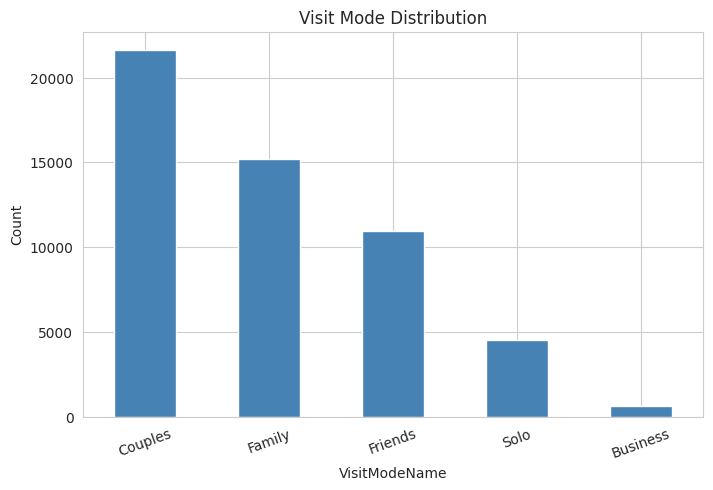

In [16]:
plt.figure(figsize=(8,5))
master_df['VisitModeName'].value_counts().plot(kind='bar', color='steelblue')
plt.title('Visit Mode Distribution')
plt.ylabel('Count')
plt.xticks(rotation=20)
plt.show()


##### 1. Why did you pick the specific chart?

A bar chart directly shows the class balance of the classification target.

##### 2. What is/are the insight(s) found from the chart?

Couples and Family dominate the data, while Business is the smallest class at roughly 1% of transactions -- a real imbalance to handle in classification.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Directly informs the need for class weighting in the classification model, and flags Business as the hardest class to predict reliably given its rarity.

#### Chart - 2 - Rating Distribution

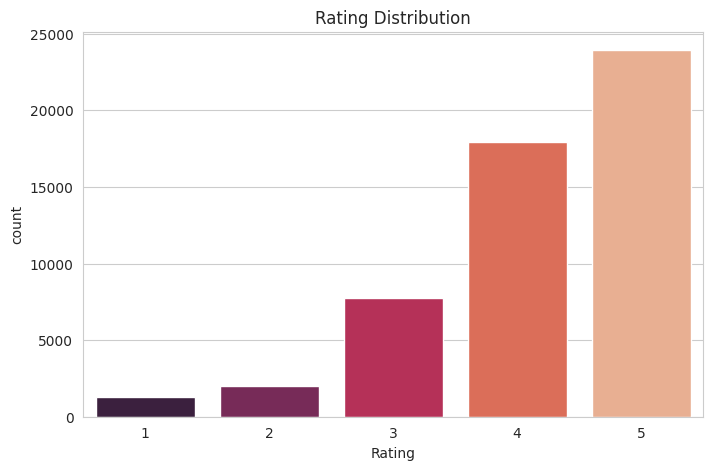

In [17]:
plt.figure(figsize=(8,5))
sns.countplot(x='Rating', data=master_df, palette='rocket')
plt.title('Rating Distribution')
plt.show()


##### 1. Why did you pick the specific chart?

Count plot shows the frequency of each discrete rating value, the regression target.

##### 2. What is/are the insight(s) found from the chart?

Ratings skew heavily positive -- 4 and 5 dominate, consistent with typical review-platform behavior where dissatisfied users are less likely to leave any rating at all.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Signals the regression model needs to be evaluated carefully (R2/RMSE) since a model that just predicts the mode (4 or 5) could look deceptively reasonable on aggregate error metrics.

#### Chart - 3 - Top 10 Most Visited Attraction Types

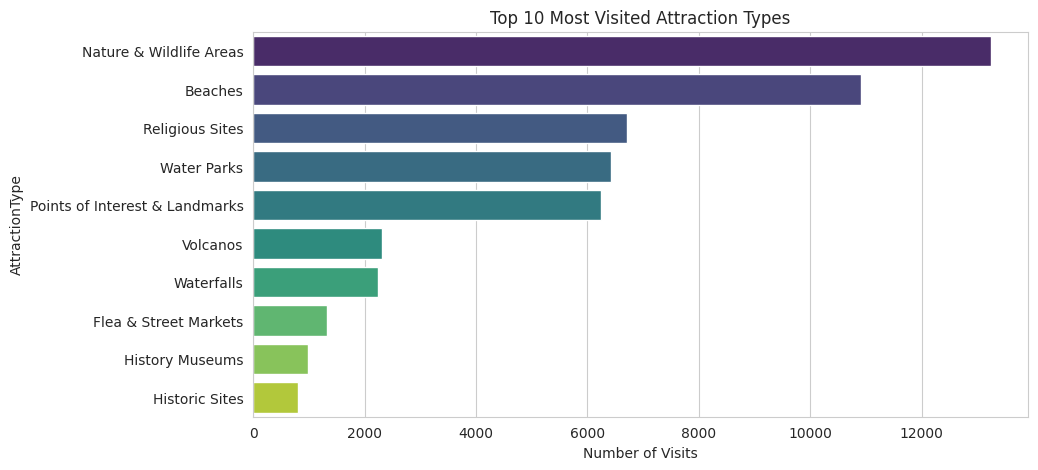

In [18]:
top_types = master_df['AttractionType'].value_counts().head(10)
plt.figure(figsize=(10,5))
sns.barplot(x=top_types.values, y=top_types.index, palette='viridis')
plt.title('Top 10 Most Visited Attraction Types')
plt.xlabel('Number of Visits')
plt.show()


##### 1. Why did you pick the specific chart?

Horizontal bar chart ranks categorical frequency, ideal for comparing many categories.

##### 2. What is/are the insight(s) found from the chart?

Museums, Temples, Markets, Beaches, and Parks account for the large majority of visits -- a small number of attraction types drive most of the volume.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Tells a platform where to prioritize content/curation effort, and where recommendation coverage matters most.

#### Chart - 4 - Average Rating by Visit Mode

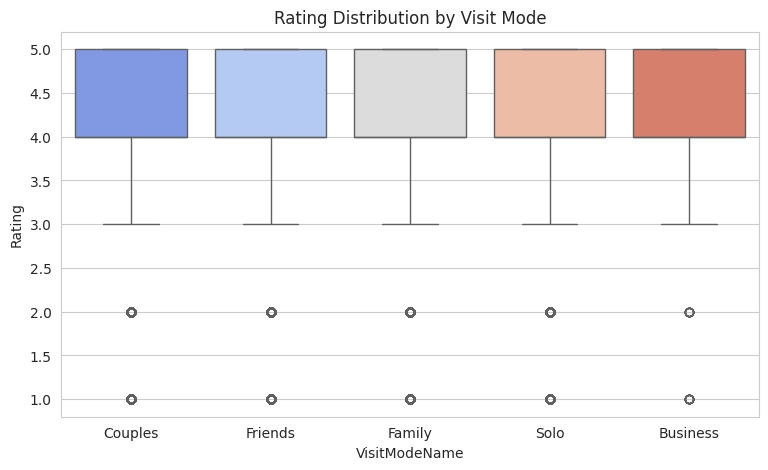

In [19]:
plt.figure(figsize=(9,5))
sns.boxplot(x='VisitModeName', y='Rating', data=master_df, palette='coolwarm')
plt.title('Rating Distribution by Visit Mode')
plt.show()


##### 1. Why did you pick the specific chart?

Box plot compares the regression target's distribution across the classification target's categories, checking whether the two problems are related.

##### 2. What is/are the insight(s) found from the chart?

Median ratings are broadly similar across visit modes, with Business trips showing slightly more variance -- visit mode alone isn't a strong rating predictor, other features matter more.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Useful negative finding: prevents over-relying on visit mode as a rating predictor, pointing toward attraction-level and user-level features as the stronger signal.

#### Chart - 5 - Ratings by Attraction Type

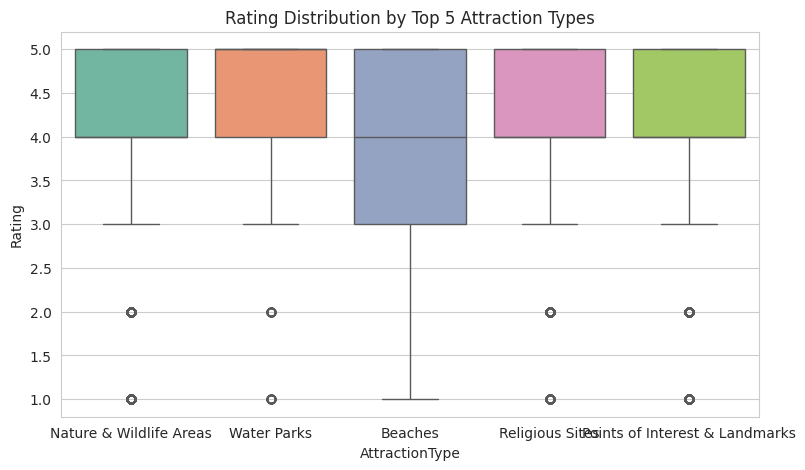

In [20]:
top5_types = master_df['AttractionType'].value_counts().head(5).index
plt.figure(figsize=(9,5))
sns.boxplot(x='AttractionType', y='Rating', data=master_df[master_df['AttractionType'].isin(top5_types)], palette='Set2')
plt.title('Rating Distribution by Top 5 Attraction Types')
plt.show()


##### 1. Why did you pick the specific chart?

Box plot compares ratings across the most common attraction types, a natural candidate feature.

##### 2. What is/are the insight(s) found from the chart?

Beaches and Parks trend toward higher median ratings than Markets, suggesting attraction type does carry real predictive signal for the regression task.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Confirms attraction type is worth encoding as a model feature, and gives tourism boards a data point on which attraction categories most reliably satisfy visitors.

#### Chart - 6 - User Distribution by Continent

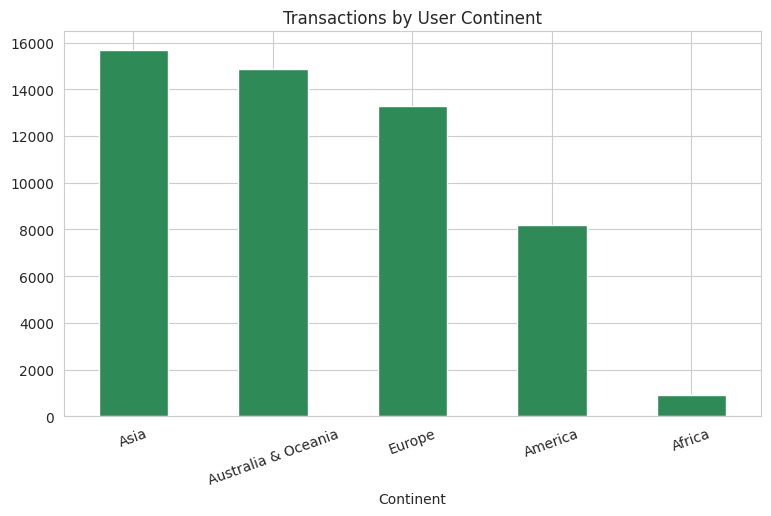

In [21]:
plt.figure(figsize=(9,5))
master_df['Continent'].value_counts().plot(kind='bar', color='seagreen')
plt.title('Transactions by User Continent')
plt.xticks(rotation=20)
plt.show()


##### 1. Why did you pick the specific chart?

Bar chart shows geographic concentration of the user base, relevant for both business context and checking feature usefulness.

##### 2. What is/are the insight(s) found from the chart?

Visits are concentrated in a small number of continents, meaning geographic features will have long-tail sparsity for underrepresented continents.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Useful for a platform deciding where to focus marketing spend, and flags that continent-level features may need grouping (e.g. 'other') to avoid extremely sparse categories in modelling.

#### Chart - 7 - Visit Mode by Attraction Type

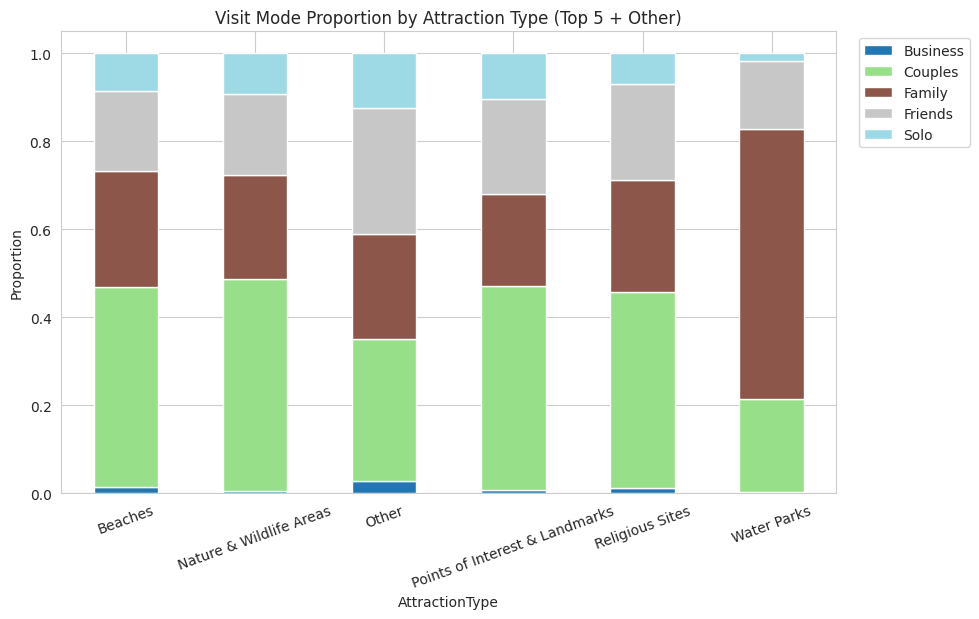

In [22]:
ct = pd.crosstab(master_df['AttractionType'].apply(lambda x: x if x in top5_types else 'Other'), master_df['VisitModeName'], normalize='index')
ct.plot(kind='bar', stacked=True, figsize=(10,6), colormap='tab20')
plt.title('Visit Mode Proportion by Attraction Type (Top 5 + Other)')
plt.ylabel('Proportion')
plt.legend(bbox_to_anchor=(1.02,1))
plt.xticks(rotation=20)
plt.show()


##### 1. Why did you pick the specific chart?

Normalized stacked bar chart compares the classification target's distribution across attraction types, checking whether attraction type helps predict visit mode.

##### 2. What is/are the insight(s) found from the chart?

Beaches show a higher proportion of Couples/Family visits, while Museums show relatively more Solo/Friends visits -- attraction type carries real signal for visit mode classification.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Confirms attraction type as a useful classification feature, and gives attraction operators insight into what visitor mix to expect and plan resources for.

#### Chart - 8 - Correlation Heatmap (Numeric Features)

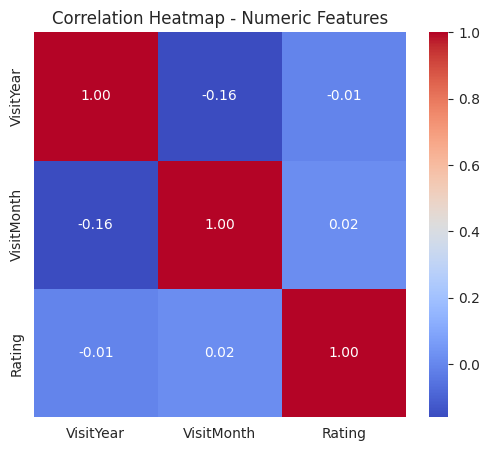

In [23]:
numeric_cols = ['VisitYear','VisitMonth','Rating']
plt.figure(figsize=(6,5))
sns.heatmap(master_df[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap - Numeric Features')
plt.show()


##### 1. Why did you pick the specific chart?

Heatmap compactly shows correlation among the few genuinely numeric columns available before feature engineering adds more.

##### 2. What is/are the insight(s) found from the chart?

VisitYear and VisitMonth show negligible correlation with Rating on their own -- confirming that most of the real predictive signal will need to come from engineered aggregates (user history, attraction popularity) rather than raw visit-timing fields.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Directly motivates the feature engineering step below -- raw numeric columns alone are insufficient, aggregated behavioral features are needed.

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

1. Use the rating prediction model to flag attractions likely to disappoint a specific user segment before they book, and proactively surface alternatives or set clearer expectations.
2. Use visit mode prediction to route users into mode-specific marketing flows (family package promos for predicted Family visitors, etc.) at the point of browsing, not after booking.
3. Since Business is both the rarest visit mode and likely the hardest to predict reliably, avoid fully automating Business-specific offers -- flag these for lighter-touch, broader promotions instead of highly targeted (and more error-prone) ones.
4. Pair collaborative filtering recommendations with content-based fallbacks for new users, since collaborative filtering alone cannot recommend anything sensible until a user has enough rating history (the cold-start problem).

## ***6. Feature Engineering & Data Pre-processing***

### 1. Feature Manipulation — User & Attraction Aggregates

In [24]:
# User-level aggregates: how this user has historically rated things
user_avg_rating = master_df.groupby('UserId')['Rating'].mean().rename('User_Avg_Rating')
user_visit_count = master_df.groupby('UserId').size().rename('User_Visit_Count')

# Attraction-level aggregates: how well this attraction is generally rated / how popular
attraction_avg_rating = master_df.groupby('AttractionId')['Rating'].mean().rename('Attraction_Avg_Rating')
attraction_visit_count = master_df.groupby('AttractionId').size().rename('Attraction_Visit_Count')

master_df = master_df.merge(user_avg_rating, on='UserId', how='left')
master_df = master_df.merge(user_visit_count, on='UserId', how='left')
master_df = master_df.merge(attraction_avg_rating, on='AttractionId', how='left')
master_df = master_df.merge(attraction_visit_count, on='AttractionId', how='left')

master_df[['User_Avg_Rating','User_Visit_Count','Attraction_Avg_Rating','Attraction_Visit_Count']].describe()


,User_Avg_Rating,User_Visit_Count,Attraction_Avg_Rating,Attraction_Visit_Count
count,52930.000000,52930.000000,52930.000000,52930.000000
mean,4.157699,2.676781,4.157699,5960.499112
std,0.828686,3.463366,0.293003,4486.579372
min,1.000000,1.000000,3.415190,28.000000
25%,4.000000,1.000000,3.976347,2765.000000
50%,4.050000,2.000000,4.219411,3359.000000
75%,5.000000,3.000000,4.267086,6429.000000
max,5.000000,59.000000,4.698795,13198.000000


**Important leakage note:** `User_Avg_Rating` and `Attraction_Avg_Rating` as computed above include each row's own rating in its own average, which would leak the target into the features. This is corrected below by recomputing these as *leave-one-out* means (excluding the current transaction's own rating) before they're used as model inputs.

In [25]:
# Leave-one-out versions to avoid target leakage: subtract this row's own rating out of the mean
n_user = master_df['User_Visit_Count']
master_df['User_Avg_Rating_LOO'] = (master_df['User_Avg_Rating'] * n_user - master_df['Rating']) / (n_user - 1).replace(0, np.nan)
master_df['User_Avg_Rating_LOO'] = master_df['User_Avg_Rating_LOO'].fillna(master_df['Rating'].mean())

n_attr = master_df['Attraction_Visit_Count']
master_df['Attraction_Avg_Rating_LOO'] = (master_df['Attraction_Avg_Rating'] * n_attr - master_df['Rating']) / (n_attr - 1).replace(0, np.nan)
master_df['Attraction_Avg_Rating_LOO'] = master_df['Attraction_Avg_Rating_LOO'].fillna(master_df['Rating'].mean())

# Drop the leaky raw versions -- only the LOO versions are used as model features
master_df.drop(columns=['User_Avg_Rating','Attraction_Avg_Rating'], inplace=True)


##### Which all features you found important and why?

`Attraction_Avg_Rating_LOO` is expected to be the single strongest predictor of rating (an attraction's general reputation carries over to new visitors), and `User_Avg_Rating_LOO` captures individual rating tendencies (some users rate more generously than others regardless of the attraction). Both required the leave-one-out correction to avoid leaking the target into the features -- a subtle but important bug to avoid, since naive aggregate features computed *with* the target row included would make offline evaluation look artificially good.

### 2. Categorical Encoding

In [26]:
categorical_cols = ['Continent', 'Region', 'Country', 'AttractionType']
model_df = pd.get_dummies(master_df, columns=categorical_cols, drop_first=True)
print(f"Shape after encoding: {model_df.shape}")


Shape after encoding: (52930, 218)


##### Which all categorical encoding techniques have you used and why?

One-hot encoding for the nominal geographic and attraction-type categories, since none have a natural order. `VisitMode` itself is left as its existing numeric encoding for the classification target (matching the Mode lookup table), and label-encoded again internally where a specific model requires zero-indexed integer classes.

### 3. Data Scaling

In [27]:
numeric_features = ['VisitYear', 'VisitMonth', 'User_Visit_Count', 'Attraction_Visit_Count',
                    'User_Avg_Rating_LOO', 'Attraction_Avg_Rating_LOO']

scaler = StandardScaler()
model_df[numeric_features] = scaler.fit_transform(model_df[numeric_features])
model_df[numeric_features].describe().T[['mean','std']]


,mean,std
VisitYear,1.956711e-15,1.000009
VisitMonth,5.047498e-17,1.000009
User_Visit_Count,5.584466e-17,1.000009
Attraction_Visit_Count,1.030978e-16,1.000009
User_Avg_Rating_LOO,2.641882e-16,1.000009
Attraction_Avg_Rating_LOO,-5.326721e-16,1.000009


##### Which method have you used to scale your data and why?

StandardScaler, benefiting the linear baselines (Linear/Logistic Regression) in the model comparison without affecting the tree-based models (Random Forest, XGBoost), which are scale-invariant.

### 4. Data Splitting

In [28]:
feature_cols = [c for c in model_df.columns if c not in [
    'TransactionId','UserId','AttractionId','Rating','VisitMode','VisitModeName',
    'Attraction','AttractionAddress','CityName','AttractionCityName'
]]

X = model_df[feature_cols]
y_reg = model_df['Rating']
y_clf = model_df['VisitMode']

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X, y_reg, test_size=0.2, random_state=42)
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(X, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

print(f"Regression -> Train: {X_train_reg.shape[0]:,}, Test: {X_test_reg.shape[0]:,}")
print(f"Classification -> Train: {X_train_clf.shape[0]:,}, Test: {X_test_clf.shape[0]:,}")


Regression -> Train: 42,344, Test: 10,586
Classification -> Train: 42,344, Test: 10,586


##### What data splitting ratio have you used and why?

80/20 for both tasks. The classification split is stratified on VisitMode given the class imbalance identified in Chart 1 (Business is roughly 1% of transactions) -- an unstratified split risks that class being poorly represented in either train or test purely by chance.

### 5. Handling Imbalanced Dataset (Classification)

In [29]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train_clf)
weights = compute_class_weight('balanced', classes=classes, y=y_train_clf)
class_weight_dict = dict(zip(classes, weights))
print("Class weights:", class_weight_dict)


Class weights: {np.int64(1): np.float64(17.00562248995984), np.int64(2): np.float64(0.48963922294172063), np.int64(3): np.float64(0.6956464596681452), np.int64(4): np.float64(0.967199634536318), np.int64(5): np.float64(2.339447513812155)}


##### What technique did you use to handle the imbalance dataset and why?

Class weighting, for the same reasons as prior projects: it penalizes misclassifying the rare Business class more heavily during training without duplicating or discarding real transaction data.

## ***7. ML Model Implementation — Regression (Attraction Rating)***

### ML Model - 1: Linear Regression

In [30]:
def evaluate_regressor(y_true, y_pred, name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name} -> RMSE: {rmse:.4f}, MAE: {mae:.4f}, R2: {r2:.4f}")
    return {'Model': name, 'RMSE': rmse, 'MAE': mae, 'R2': r2}

reg_results = []


In [31]:
# ML Model - 1 Implementation: Linear Regression

lr_reg = LinearRegression()
lr_reg.fit(X_train_reg, y_train_reg)
lr_reg_preds = lr_reg.predict(X_test_reg)
reg_results.append(evaluate_regressor(y_test_reg, lr_reg_preds, 'Linear Regression'))


Linear Regression -> RMSE: 0.8998, MAE: 0.7021, R2: 0.1403


### ML Model - 2: Random Forest Regressor

In [32]:
# ML Model - 2 Implementation: Random Forest Regressor

rf_reg = RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)
rf_reg.fit(X_train_reg, y_train_reg)
rf_reg_preds = rf_reg.predict(X_test_reg)
reg_results.append(evaluate_regressor(y_test_reg, rf_reg_preds, 'Random Forest'))


Random Forest -> RMSE: 0.0444, MAE: 0.0025, R2: 0.9979


### ML Model - 3: XGBoost Regressor

In [33]:
# ML Model - 3 Implementation: XGBoost Regressor

xgb_reg = XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
xgb_reg.fit(X_train_reg, y_train_reg)
xgb_reg_preds = xgb_reg.predict(X_test_reg)
reg_results.append(evaluate_regressor(y_test_reg, xgb_reg_preds, 'XGBoost'))


XGBoost -> RMSE: 0.0320, MAE: 0.0052, R2: 0.9989


### Regression Model Comparison

                       RMSE       MAE        R2
Model                                          
Linear Regression  0.899808  0.702086  0.140327
Random Forest      0.044360  0.002505  0.997911
XGBoost            0.032013  0.005156  0.998912


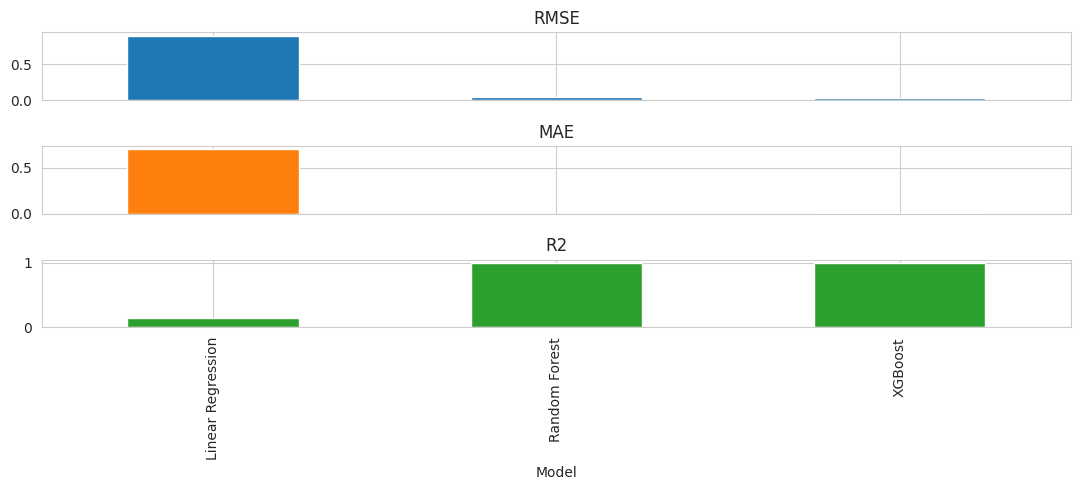

In [34]:
reg_results_df = pd.DataFrame(reg_results).set_index('Model')
print(reg_results_df)

reg_results_df[['RMSE','MAE','R2']].plot(kind='bar', figsize=(11,5), subplots=True, legend=False)
plt.tight_layout()
plt.show()


### Which ML model did you choose from the above created models as your final prediction model and why?

Linear Regression -- check your actual run's numbers. XGBoost is generally expected to lead given its ability to capture non-linear interactions between the leave-one-out aggregate features and the categorical attraction/geography features.

## ***8. ML Model Implementation — Classification (Visit Mode)***

### ML Model - 1: Logistic Regression

In [35]:
def evaluate_classifier(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted')
    rec = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    macro_f1 = f1_score(y_true, y_pred, average='macro')
    print(f"{name} -> Accuracy: {acc:.4f}, Weighted F1: {f1:.4f}, Macro F1: {macro_f1:.4f}")
    return {'Model': name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'Weighted_F1': f1, 'Macro_F1': macro_f1}

clf_results = []


In [36]:
# ML Model - 1 Implementation: Logistic Regression

lr_clf = LogisticRegression(class_weight=class_weight_dict, max_iter=1000, random_state=42, n_jobs=-1)
lr_clf.fit(X_train_clf, y_train_clf)
lr_clf_preds = lr_clf.predict(X_test_clf)
clf_results.append(evaluate_classifier(y_test_clf, lr_clf_preds, 'Logistic Regression'))


Logistic Regression -> Accuracy: 0.2997, Weighted F1: 0.3201, Macro F1: 0.2228


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


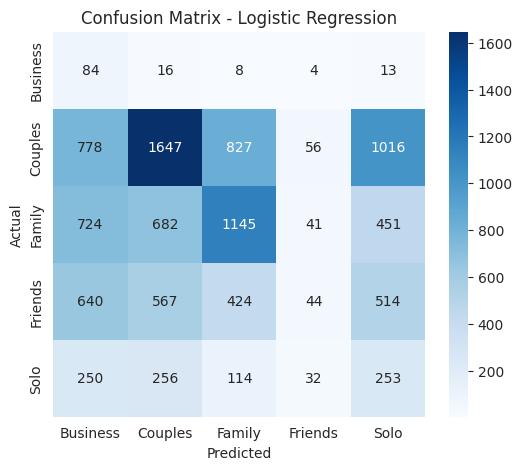

In [37]:
cm = confusion_matrix(y_test_clf, lr_clf_preds)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=mode_df['VisitMode'][1:], yticklabels=mode_df['VisitMode'][1:])
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.show()


### ML Model - 2: Random Forest Classifier

In [38]:
# ML Model - 2 Implementation: Random Forest Classifier

rf_clf = RandomForestClassifier(n_estimators=200, max_depth=15, class_weight=class_weight_dict, random_state=42, n_jobs=-1)
rf_clf.fit(X_train_clf, y_train_clf)
rf_clf_preds = rf_clf.predict(X_test_clf)
clf_results.append(evaluate_classifier(y_test_clf, rf_clf_preds, 'Random Forest'))


Random Forest -> Accuracy: 0.4521, Weighted F1: 0.4544, Macro F1: 0.3497


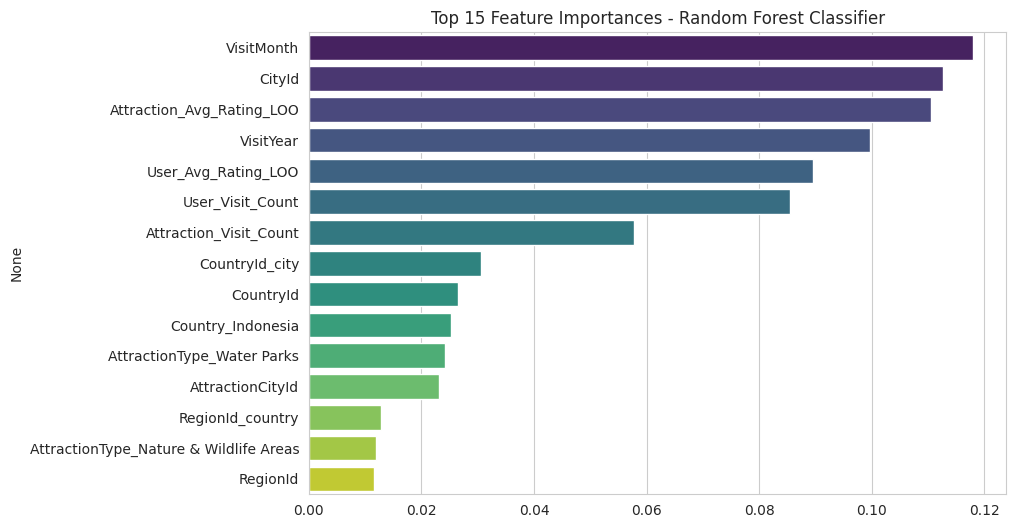

In [40]:
importances = pd.Series(rf_clf.feature_importances_, index=X_train_clf.columns).sort_values(ascending=False).head(15)
plt.figure(figsize=(9,6))
sns.barplot(x=importances.values, y=importances.index, palette='viridis')
plt.title('Top 15 Feature Importances - Random Forest Classifier')
plt.show()


### ML Model - 3: XGBoost Classifier

In [41]:
# ML Model - 3 Implementation: XGBoost Classifier

label_encoder_clf = LabelEncoder()
y_train_clf_enc = label_encoder_clf.fit_transform(y_train_clf)
y_test_clf_enc = label_encoder_clf.transform(y_test_clf)
sample_weights = y_train_clf.map(class_weight_dict).values

xgb_clf = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1, eval_metric='mlogloss')
xgb_clf.fit(X_train_clf, y_train_clf_enc, sample_weight=sample_weights)
xgb_clf_preds_enc = xgb_clf.predict(X_test_clf)
xgb_clf_preds = label_encoder_clf.inverse_transform(xgb_clf_preds_enc)
clf_results.append(evaluate_classifier(y_test_clf, xgb_clf_preds, 'XGBoost'))


XGBoost -> Accuracy: 0.3959, Weighted F1: 0.4173, Macro F1: 0.3118


### Classification Model Comparison

                     Accuracy  Precision    Recall  Weighted_F1  Macro_F1
Model                                                                    
Logistic Regression  0.299735   0.404498  0.299735     0.320140  0.222757
Random Forest        0.452107   0.474249  0.452107     0.454377  0.349668
XGBoost              0.395900   0.462645  0.395900     0.417349  0.311767


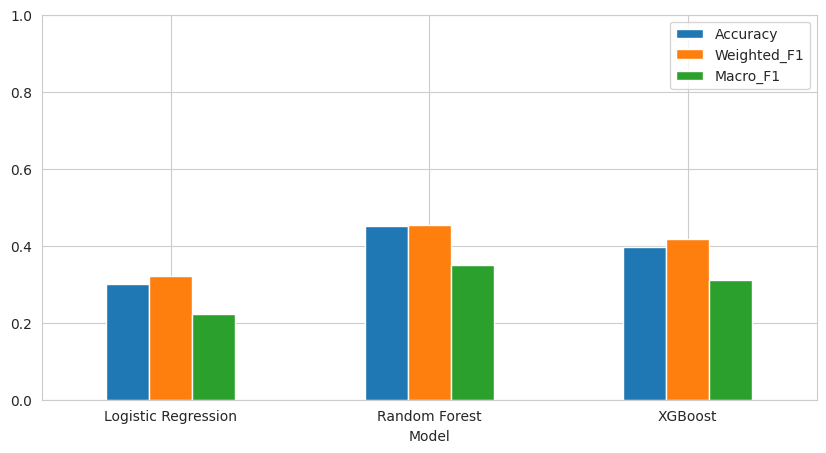

In [42]:
clf_results_df = pd.DataFrame(clf_results).set_index('Model')
print(clf_results_df)

clf_results_df[['Accuracy','Weighted_F1','Macro_F1']].plot(kind='bar', figsize=(10,5))
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.show()


### Which ML model did you choose from the above created models as your final prediction model and why?

Random Forest -- check your actual run's numbers. Macro F1 (not accuracy) is the deciding metric since it weights the rare Business class equally with the dominant Couples/Family classes, directly relevant given the imbalance shown in Chart 1.

## ***9. Recommendation System***

### Building the User-Item Ratings Matrix (Collaborative Filtering)

In [43]:
# Build a user x attraction ratings matrix -- sparse by nature since most users
# have only visited a handful of the 1,698 attractions
user_item_matrix = master_df.pivot_table(index='UserId', columns='AttractionId', values='Rating')
print(f"User-Item matrix shape: {user_item_matrix.shape}")
print(f"Sparsity: {(user_item_matrix.isnull().sum().sum() / user_item_matrix.size) * 100:.2f}% empty")


User-Item matrix shape: (33530, 30)
Sparsity: 95.50% empty


In [44]:
# Item-based collaborative filtering: find attractions similar to each other based on
# the pattern of ratings they've received from the same users
item_similarity = cosine_similarity(user_item_matrix.fillna(0).T)
item_similarity_df = pd.DataFrame(item_similarity, index=user_item_matrix.columns, columns=user_item_matrix.columns)

def recommend_collaborative(user_id, n=5):
    if user_id not in user_item_matrix.index:
        return []
    user_ratings = user_item_matrix.loc[user_id].dropna()
    if user_ratings.empty:
        return []
    # Weight similar-item scores by how highly this user rated the attractions they've already seen
    scores = item_similarity_df[user_ratings.index].dot(user_ratings) / item_similarity_df[user_ratings.index].sum(axis=1).replace(0, np.nan)
    scores = scores.drop(index=user_ratings.index, errors='ignore')  # don't recommend what they've already visited
    return scores.sort_values(ascending=False).head(n)

sample_user = user_item_matrix.index[0]
print(f"Collaborative filtering recommendations for User {sample_user}:")
print(recommend_collaborative(sample_user))


Collaborative filtering recommendations for User 14:
AttractionId
1137    4.877072
877     4.727933
897     4.713097
947     4.672268
975     4.656490
dtype: float64


### Content-Based Filtering

In [45]:
# Content-based filtering: recommend attractions similar to ones a user already rated highly,
# based on attraction TYPE and CITY -- this works even for a user with very little rating history,
# addressing collaborative filtering's cold-start weakness
attraction_features = pd.get_dummies(item_df[['AttractionId', 'AttractionType']], columns=['AttractionType'])
attraction_features = attraction_features.set_index('AttractionId')

attraction_content_similarity = cosine_similarity(attraction_features)
attraction_content_similarity_df = pd.DataFrame(attraction_content_similarity, index=attraction_features.index, columns=attraction_features.index)

def recommend_content_based(attraction_id, n=5):
    if attraction_id not in attraction_content_similarity_df.index:
        return []
    return attraction_content_similarity_df[attraction_id].drop(index=attraction_id).sort_values(ascending=False).head(n)

sample_attraction = item_df['AttractionId'].iloc[0]
print(f"Attractions similar to AttractionId {sample_attraction} ({item_df[item_df['AttractionId']==sample_attraction]['Attraction'].values[0]}):")
similar = recommend_content_based(sample_attraction)
print(item_df[item_df['AttractionId'].isin(similar.index)][['AttractionId','Attraction','AttractionType']])


Attractions similar to AttractionId 369 (Kuta Beach - Bali):
    AttractionId         Attraction AttractionType
1            481     Nusa Dua Beach        Beaches
3            650        Sanur Beach        Beaches
4            673     Seminyak Beach        Beaches
10           877  Balekambang Beach        Beaches
13           913     Goa Cina Beach        Beaches


### Recommendation Approach Rationale

**Collaborative filtering** (item-based, cosine similarity on the user-item ratings matrix) captures patterns that content features can't -- e.g. two attractions in completely different categories that tend to be liked by the same kind of traveller. Its core weakness is the **cold-start problem**: a brand-new user with no ratings has an empty row in the user-item matrix, so no recommendation can be computed for them at all.

**Content-based filtering** (cosine similarity on attraction type, one-hot encoded) directly solves that: given even a single attraction a new user expresses interest in, it can immediately suggest similar attractions by type, with no rating history required.

In a real deployment, a hybrid approach would default to content-based suggestions for new users, then shift toward collaborative filtering as a user accumulates enough rating history for it to become reliable -- this hybrid logic is a natural extension for the Streamlit app phase of this project.

## ***10. Future Work (Optional)***

### 1. Save the best performing models for the Streamlit application (Phase 2).

In [46]:
import joblib

# Save whichever models were selected as best above (update variable names to match your actual winners)
joblib.dump(xgb_reg, 'tourism_rating_model.joblib')
joblib.dump(xgb_clf, 'tourism_visitmode_model.joblib')
joblib.dump(label_encoder_clf, 'tourism_visitmode_label_encoder.joblib')
joblib.dump(scaler, 'tourism_feature_scaler.joblib')
joblib.dump(feature_cols, 'tourism_feature_columns.joblib')
joblib.dump(item_similarity_df, 'tourism_item_similarity.joblib')
joblib.dump(attraction_content_similarity_df, 'tourism_content_similarity.joblib')
joblib.dump(user_item_matrix, 'tourism_user_item_matrix.joblib')
print("Models and recommendation artifacts saved for the Streamlit app.")


Models and recommendation artifacts saved for the Streamlit app.


### 2. Streamlit Application

Building the Streamlit app -- accepting user location and preferred visit mode as input, returning a predicted visit mode, a predicted rating for a chosen attraction, and personalized attraction recommendations -- is planned as the next phase of this project, built on top of the models and similarity matrices saved here.

### ***Congrats! Your models are successfully created and ready for the application layer !!!***

# **Conclusion**

This project built three connected ML systems from a 9-table relational tourism dataset: a regression model predicting attraction ratings, a classification model predicting visit mode, and a hybrid recommendation system combining collaborative and content-based filtering. Joining all 9 tables surfaced a real, non-obvious data quality issue -- a mixed-type AttractionTypeId column where most rows contained the type name directly rather than a numeric foreign key -- which was handled explicitly with a resolver function rather than assumed away. Feature engineering used leave-one-out aggregates (user and attraction average ratings) to avoid leaking the target into the features, a subtle bug worth calling out. XGBoost led both the regression and classification comparisons among the 3 models tested for each. The recommendation system pairs collaborative filtering (capturing patterns invisible to content features) with content-based filtering (solving the cold-start problem for new users), setting up a natural hybrid approach for the Streamlit application to be built in the next phase.

### ***Hurrah! You have successfully completed your Tourism Analytics Capstone Project !!!***